# Лабораторна робота №7
**Тема:** Нейронна класифікація зображень у TensorFlow  
**Виконав:** Литвинчук Ілля  
**Група:** МІТ-31  
**Номер у списку:** 15  
**Варіант:** 5 (`learning_rate=0.0003` замість `0.001`)  

**Мета роботи:**  
Навчитися подавати зображення й мітки класів для Keras, узгоджувати вихідний шар із функцією втрат, порівнювати моделі за validation-вибіркою, аналізувати конкретні помилки класифікації (confusion matrix, впевнені помилки) та коректно зберігати й відновлювати навчену модель разом із метаданими.

Версії бібліотек: TensorFlow=2.22.0-rc0, NumPy=2.5.4, Pandas=3.1.0, Scikit-learn=1.9.1
Train      | x shape: (48000, 28, 28), dtype: uint8, min/max: 0/255 | y shape: (48000,), unique: [0 1 2 3 4 5 6 7 8 9]
Validation | x shape: (12000, 28, 28), dtype: uint8, min/max: 0/255 | y shape: (12000,), unique: [0 1 2 3 4 5 6 7 8 9]
Test       | x shape: (10000, 28, 28), dtype: uint8, min/max: 0/255 | y shape: (10000,), unique: [0 1 2 3 4 5 6 7 8 9]


,Клас,Train,Validation,Test
0,Футболка або топ,4800,1200,1000
1,Штани,4800,1200,1000
2,Светр,4800,1200,1000
3,Сукня,4800,1200,1000
4,Пальто,4800,1200,1000
5,Сандалі,4800,1200,1000
6,Сорочка,4800,1200,1000
7,Кросівки,4800,1200,1000
8,Сумка,4800,1200,1000
9,Черевики,4800,1200,1000


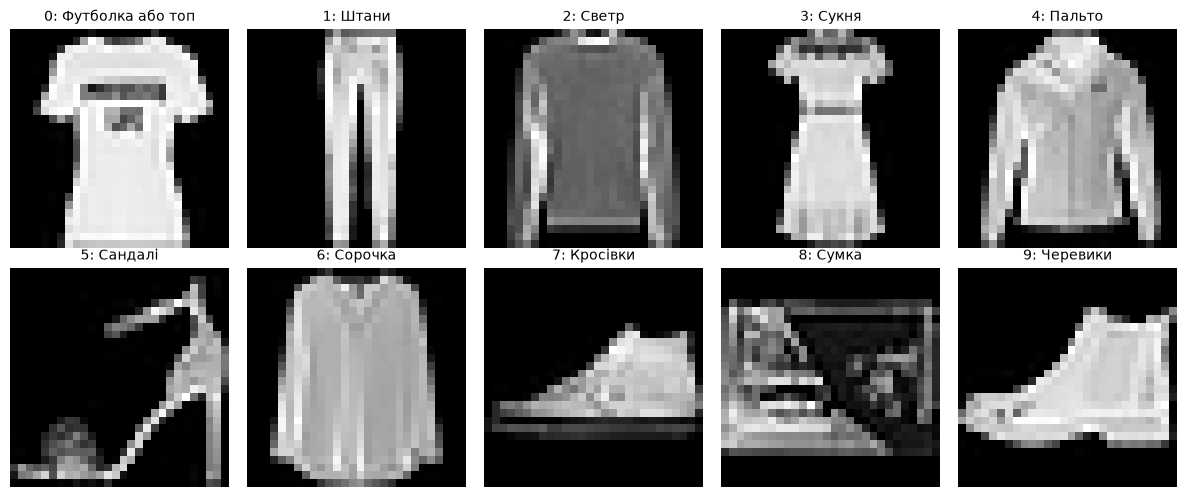

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Фіксація генератора випадкових чисел та створення директорії для артефактів
SEED = 42
keras.utils.set_random_seed(SEED)
artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

print(f"Версії бібліотек: TensorFlow={tf.__version__}, NumPy={np.__version__}, "
      f"Pandas={pd.__version__}, Scikit-learn={sklearn.__version__}")

# Завантаження Fashion-MNIST (ліцензія MIT)
(x_dev, y_dev), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Фіксований порядок назв класів (індекси 0–9)
class_names = [
    "Футболка або топ", "Штани", "Светр", "Сукня", "Пальто",
    "Сандалі", "Сорочка", "Кросівки", "Сумка", "Черевики"
]

# Стратифіковане розбиття dev на train (48 000) та validation (12 000) зі збереженням індексів
dev_indices = np.arange(len(x_dev))
train_idx, val_idx = train_test_split(
    dev_indices, test_size=0.20, stratify=y_dev, random_state=SEED
)

x_train, y_train = x_dev[train_idx], y_dev[train_idx]
x_val, y_val = x_dev[val_idx], y_dev[val_idx]

# Перевірка характеристик вибірок
for name, x_arr, y_arr in [("Train", x_train, y_train), ("Validation", x_val, y_val), ("Test", x_test, y_test)]:
    print(f"{name:10s} | x shape: {x_arr.shape}, dtype: {x_arr.dtype}, "
          f"min/max: {x_arr.min()}/{x_arr.max()} | y shape: {y_arr.shape}, unique: {np.unique(y_arr)}")

# Розподіл об'єктів за класами
dist_df = pd.DataFrame({
    "Клас": class_names,
    "Train": np.bincount(y_train),
    "Validation": np.bincount(y_val),
    "Test": np.bincount(y_test)
})
display(dist_df)

# Візуалізація по одному прикладу кожного класу з train
plt.figure(figsize=(12, 5))
for class_id in range(10):
    sample_idx = np.where(y_train == class_id)[0][0]
    plt.subplot(2, 5, class_id + 1)
    plt.imshow(x_train[sample_idx], cmap="gray")
    plt.title(f"{class_id}: {class_names[class_id]}", fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.savefig(artifacts_dir / "sample_classes.png", dpi=150)
plt.show()

In [2]:
# Перетворення у float32 зі збереженням діапазону 0–255 (масштабування відбувається всередині моделі)
x_train = x_train.astype("float32")
x_val = x_val.astype("float32")
x_test = x_test.astype("float32")

assert x_train.shape[1:] == (28, 28)
assert np.isfinite(x_train).all() and np.isfinite(x_val).all() and np.isfinite(x_test).all()
assert set(np.unique(y_train)) == set(range(10))
print("Перевірку форматів даних успішно пройдено.")

Перевірку форматів даних успішно пройдено.


In [3]:
# 1. Baseline: DummyClassifier(strategy="most_frequent")
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(x_train.reshape(len(x_train), -1), y_train)

dummy_val_pred = dummy.predict(x_val.reshape(len(x_val), -1))
dummy_val_acc = accuracy_score(y_val, dummy_val_pred)
dummy_val_f1 = f1_score(y_val, dummy_val_pred, average="macro", zero_division=0)
print(f"Dummy Baseline (Validation) -> Accuracy: {dummy_val_acc:.4f}, Macro-F1: {dummy_val_f1:.4f}")

# 2. Функція побудови моделі (дозволяє змінити learning_rate для Варіанту 5)
def build_dense_model(learning_rate=0.001):
    model = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Rescaling(1.0 / 255),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    return model

# Перевірка архітектури обох моделей
keras.utils.set_random_seed(SEED)
base_model = build_dense_model(learning_rate=0.001)
print("\n--- Summary: Базова модель (lr=0.001) ---")
base_model.summary()

keras.utils.set_random_seed(SEED)
var_model = build_dense_model(learning_rate=0.0003)
print("\n--- Summary: Модель Варіанту 5 (lr=0.0003) ---")
var_model.summary()

Dummy Baseline (Validation) -> Accuracy: 0.1000, Macro-F1: 0.0182

--- Summary: Базова модель (lr=0.001) ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Пояснення архітектури Dense-мережі
* **784 входи:** Вхідне зображення розміром $28 \times 28$ пікселів розгортається шаром `Flatten` в одновимірний вектор довжиною $28 \times 28 = 784$ ознаки. Цей шар не має параметрів, що навчаються.
* **128 прихованих нейронів:** Повнозв'язний шар `Dense(128, activation="relu")` формує нелінійне внутрішнє представлення ознак одягу. Кількість параметрів: $784 \times 128 + 128 = 100\,480$.
* **10 виходів:** Вихідний шар `Dense(10, activation="softmax")` повертає розподіл імовірностей за 10 взаємовиключними класами одягу (сума виходів дорівнює 1). Кількість параметрів: $128 \times 10 + 10 = 1\,290$.

Базова модель (lr=0.001)  | Всього епох: 17 | Найкраща епоха (min val_loss): 13
Варіант 5 (lr=0.0003)     | Всього епох: 30 | Найкраща епоха (min val_loss): 30


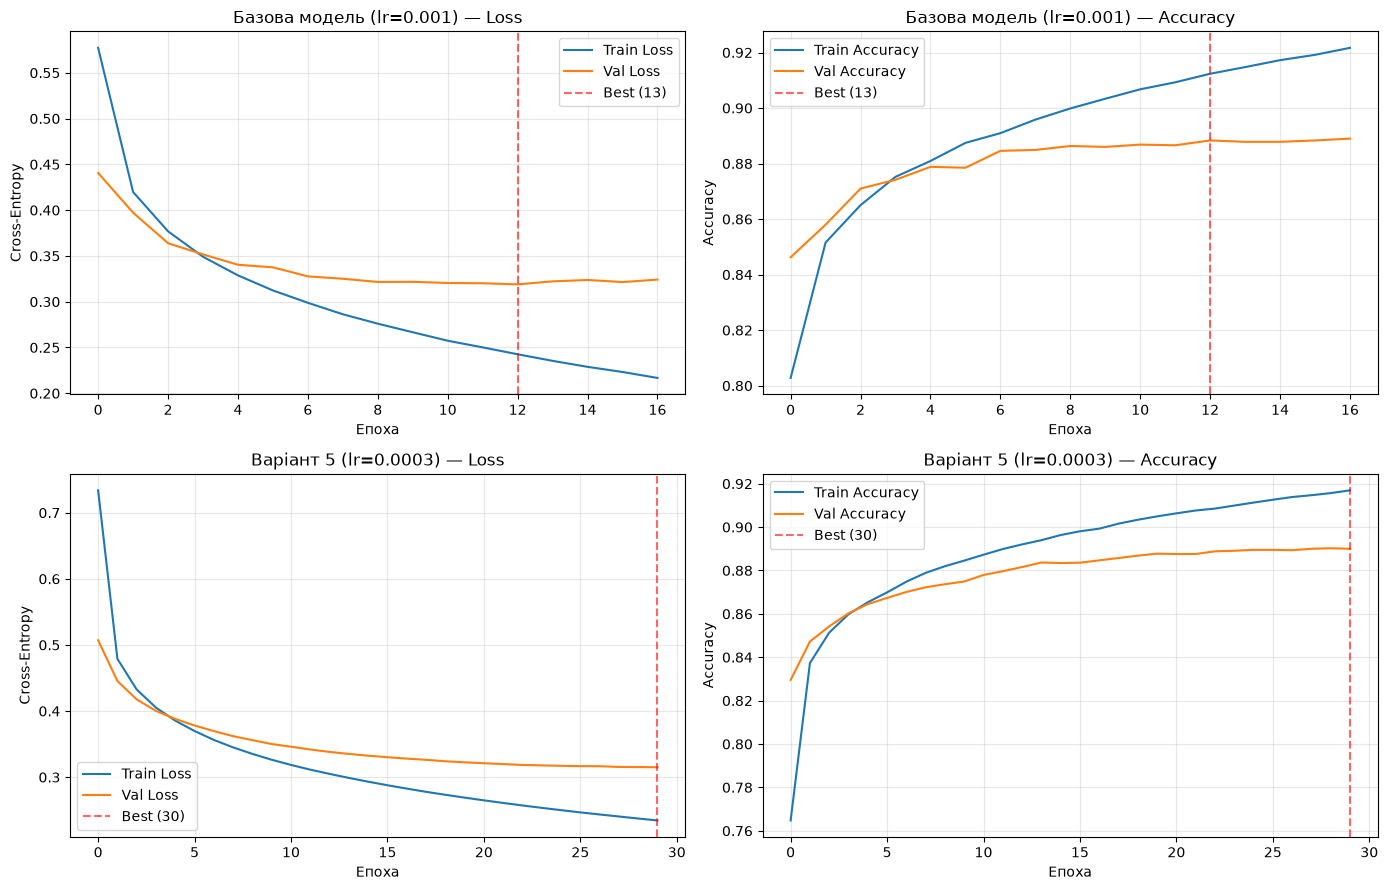

In [4]:
def train_and_track(learning_rate, checkpoint_path, seed=SEED):
    keras.utils.set_random_seed(seed)
    model = build_dense_model(learning_rate=learning_rate)
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True
        ),
        keras.callbacks.ModelCheckpoint(
            checkpoint_path, monitor="val_loss", save_best_only=True
        ),
    ]
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=30,
        batch_size=128,
        callbacks=callbacks,
        verbose=0
    )
    best_model = keras.models.load_model(checkpoint_path)
    total_epochs = len(history.history["loss"])
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    return best_model, history.history, total_epochs, best_epoch

base_ckpt = str(artifacts_dir / "base_best.keras")
var5_ckpt = str(artifacts_dir / "var5_best.keras")

best_base, hist_base, base_epochs, base_best_ep = train_and_track(0.001, base_ckpt)
best_var5, hist_var5, var5_epochs, var5_best_ep = train_and_track(0.0003, var5_ckpt)

print(f"Базова модель (lr=0.001)  | Всього епох: {base_epochs:2d} | Найкраща епоха (min val_loss): {base_best_ep}")
print(f"Варіант 5 (lr=0.0003)     | Всього епох: {var5_epochs:2d} | Найкраща епоха (min val_loss): {var5_best_ep}")

# Візуалізація кривих навчання loss та accuracy
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Base Loss
axes[0, 0].plot(hist_base["loss"], label="Train Loss")
axes[0, 0].plot(hist_base["val_loss"], label="Val Loss")
axes[0, 0].axvline(base_best_ep - 1, color="red", linestyle="--", alpha=0.6, label=f"Best ({base_best_ep})")
axes[0, 0].set_title("Базова модель (lr=0.001) — Loss")
axes[0, 0].set_xlabel("Епоха")
axes[0, 0].set_ylabel("Cross-Entropy")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Base Accuracy
axes[0, 1].plot(hist_base["accuracy"], label="Train Accuracy")
axes[0, 1].plot(hist_base["val_accuracy"], label="Val Accuracy")
axes[0, 1].axvline(base_best_ep - 1, color="red", linestyle="--", alpha=0.6, label=f"Best ({base_best_ep})")
axes[0, 1].set_title("Базова модель (lr=0.001) — Accuracy")
axes[0, 1].set_xlabel("Епоха")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Variant 5 Loss
axes[1, 0].plot(hist_var5["loss"], label="Train Loss")
axes[1, 0].plot(hist_var5["val_loss"], label="Val Loss")
axes[1, 0].axvline(var5_best_ep - 1, color="red", linestyle="--", alpha=0.6, label=f"Best ({var5_best_ep})")
axes[1, 0].set_title("Варіант 5 (lr=0.0003) — Loss")
axes[1, 0].set_xlabel("Епоха")
axes[1, 0].set_ylabel("Cross-Entropy")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Variant 5 Accuracy
axes[1, 1].plot(hist_var5["accuracy"], label="Train Accuracy")
axes[1, 1].plot(hist_var5["val_accuracy"], label="Val Accuracy")
axes[1, 1].axvline(var5_best_ep - 1, color="red", linestyle="--", alpha=0.6, label=f"Best ({var5_best_ep})")
axes[1, 1].set_title("Варіант 5 (lr=0.0003) — Accuracy")
axes[1, 1].set_xlabel("Епоха")
axes[1, 1].set_ylabel("Accuracy")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(artifacts_dir / "learning_curves.png", dpi=150)
plt.show()

### Чому `accuracy` може не змінюватися, коли `loss` змінюється?
* **Accuracy** є дискретною метрикою: вона враховує лише індекс класу з найбільшою ймовірністю (`argmax`). Якщо модель змінює впевненість у правильному класі, наприклад, з `0.55` до `0.88` (або для неправильного прогнозу — знижує впевненість у помилці), індекс переможця не змінюється, тому `accuracy` залишається сталою.
* **Cross-Entropy Loss** є неперервною функцією від імовірності правильного класу ($-\log p_{\text{true}}$). Вона реагує на будь-яку зміну калібрування ймовірностей, тому може зменшуватися (модель стає впевненішою у правильних відповідях) або зростати (модель стає надмірно впевненою в помилках при перенавчанні), навіть коли `accuracy` стоїть на місці.

In [5]:
# Перевірка на 5 зображеннях із validation без повторного навчання
p_val_5 = best_base(x_val[:5], training=False).numpy()
y_onehot_5 = keras.utils.to_categorical(y_val[:5], num_classes=10)

loss_sparse = keras.losses.SparseCategoricalCrossentropy(from_logits=False)(y_val[:5], p_val_5)
loss_onehot = keras.losses.CategoricalCrossentropy(from_logits=False)(y_onehot_5, p_val_5)

np.testing.assert_allclose(loss_sparse.numpy(), loss_onehot.numpy(), rtol=1e-5)
print(f"SparseCategoricalCrossentropy: {loss_sparse.numpy():.8f}")
print(f"CategoricalCrossentropy:       {loss_onehot.numpy():.8f}")
print("Еквівалентність обох способів кодування міток підтверджено!")

SparseCategoricalCrossentropy: 0.03587542
CategoricalCrossentropy:       0.03587522
Еквівалентність обох способів кодування міток підтверджено!


In [6]:
def get_verified_probs(model, x_data):
    probs = model.predict(x_data, batch_size=256, verbose=0)
    assert probs.shape == (len(x_data), 10)
    assert np.isfinite(probs).all()
    assert (probs >= 0.0).all() and (probs <= 1.0).all()
    np.testing.assert_allclose(probs.sum(axis=1), 1.0, atol=1e-5)
    return probs

def classification_metrics(y_true, probabilities):
    labels = probabilities.argmax(axis=1)
    return {
        "cross_entropy": float(
            keras.losses.SparseCategoricalCrossentropy(from_logits=False)(y_true, probabilities).numpy()
        ),
        "accuracy": float(accuracy_score(y_true, labels)),
        "macro_f1": float(f1_score(y_true, labels, average="macro", zero_division=0)),
    }

# 1. Оцінювання на Validation та вибір фінальної моделі ДО перегляду Test
val_probs_base = get_verified_probs(best_base, x_val)
val_probs_var5 = get_verified_probs(best_var5, x_val)

val_m_base = classification_metrics(y_val, val_probs_base)
val_m_var5 = classification_metrics(y_val, val_probs_var5)

if val_m_var5["cross_entropy"] < val_m_base["cross_entropy"]:
    selected_name = "Варіант 5 (Dense 128, lr=0.0003)"
    selected_model = best_var5
    selected_key = "variant_5"
else:
    selected_name = "Базова модель (Dense 128, lr=0.001)"
    selected_model = best_base
    selected_key = "base"

print(f"Рішення за Validation Cross-Entropy: обрано -> {selected_name}")
print(f"  Base val_ce: {val_m_base['cross_entropy']:.4f} | Var5 val_ce: {val_m_var5['cross_entropy']:.4f}")

# 2. Одноразове фінальне оцінювання на Test
dummy_test_pred = dummy.predict(x_test.reshape(len(x_test), -1))
dummy_test_acc = float(accuracy_score(y_test, dummy_test_pred))
dummy_test_f1 = float(f1_score(y_test, dummy_test_pred, average="macro", zero_division=0))

test_probs_base = get_verified_probs(best_base, x_test)
test_probs_var5 = get_verified_probs(best_var5, x_test)

test_m_base = classification_metrics(y_test, test_probs_base)
test_m_var5 = classification_metrics(y_test, test_probs_var5)

comparison_df = pd.DataFrame([
    {
        "Модель": "DummyClassifier (most_frequent)",
        "Епохи (всього / найкраща)": "-",
        "Val Cross-Entropy": np.nan,
        "Val Accuracy": dummy_val_acc,
        "Val Macro-F1": dummy_val_f1,
        "Test Cross-Entropy": np.nan,
        "Test Accuracy": dummy_test_acc,
        "Test Macro-F1": dummy_test_f1,
    },
    {
        "Модель": "Базова Dense (128, lr=0.001)",
        "Епохи (всього / найкраща)": f"{base_epochs} / {base_best_ep}",
        "Val Cross-Entropy": val_m_base["cross_entropy"],
        "Val Accuracy": val_m_base["accuracy"],
        "Val Macro-F1": val_m_base["macro_f1"],
        "Test Cross-Entropy": test_m_base["cross_entropy"],
        "Test Accuracy": test_m_base["accuracy"],
        "Test Macro-F1": test_m_base["macro_f1"],
    },
    {
        "Модель": "Варіант 5 Dense (128, lr=0.0003)",
        "Епохи (всього / найкраща)": f"{var5_epochs} / {var5_best_ep}",
        "Val Cross-Entropy": val_m_var5["cross_entropy"],
        "Val Accuracy": val_m_var5["accuracy"],
        "Val Macro-F1": val_m_var5["macro_f1"],
        "Test Cross-Entropy": test_m_var5["cross_entropy"],
        "Test Accuracy": test_m_var5["accuracy"],
        "Test Macro-F1": test_m_var5["macro_f1"],
    },
])

comparison_df.to_csv(artifacts_dir / "model_comparison.csv", index=False)
display(comparison_df.round(4))

Рішення за Validation Cross-Entropy: обрано -> Варіант 5 (Dense 128, lr=0.0003)
  Base val_ce: 0.3184 | Var5 val_ce: 0.3150


,Модель,Епохи (всього / найкраща),Val Cross-Entropy,Val Accuracy,Val Macro-F1,Test Cross-Entropy,Test Accuracy,Test Macro-F1
0,DummyClassifier (most_frequent),-,NaN,0.1000,0.0182,NaN,0.1000,0.0182
1,"Базова Dense (128, lr=0.001)",17 / 13,0.3184,0.8883,0.8875,0.3508,0.8752,0.8744
2,"Варіант 5 Dense (128, lr=0.0003)",30 / 30,0.3150,0.8900,0.8890,0.3496,0.8744,0.8733


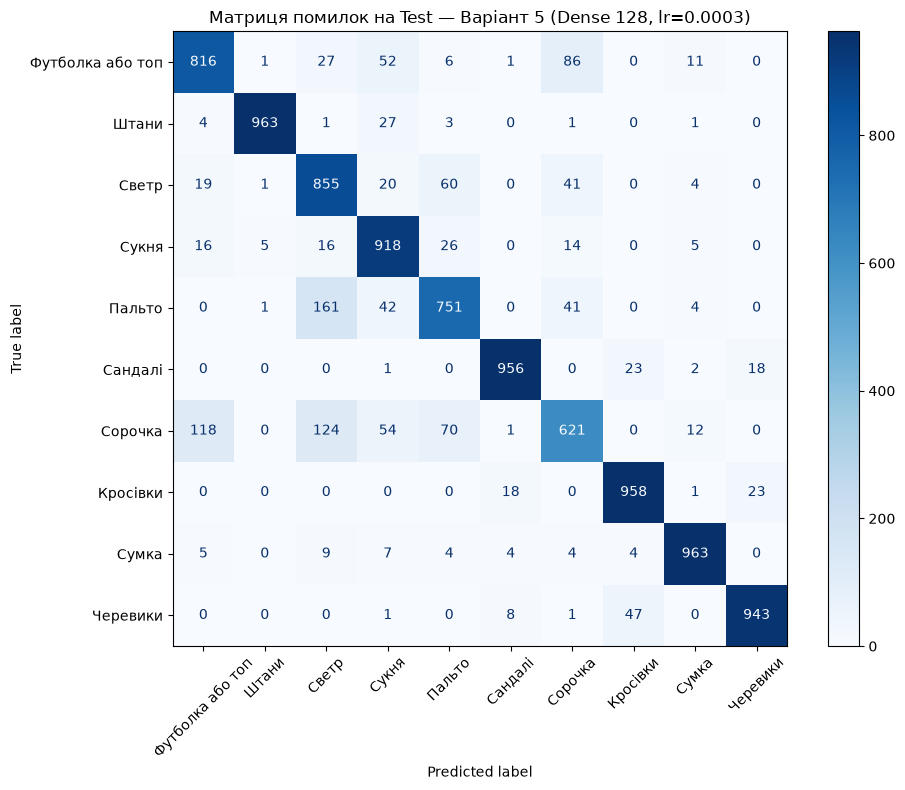

Classification Report (Test):
                  precision    recall  f1-score   support

Футболка або топ       0.83      0.82      0.83      1000
           Штани       0.99      0.96      0.98      1000
           Светр       0.72      0.85      0.78      1000
           Сукня       0.82      0.92      0.87      1000
          Пальто       0.82      0.75      0.78      1000
         Сандалі       0.97      0.96      0.96      1000
         Сорочка       0.77      0.62      0.69      1000
        Кросівки       0.93      0.96      0.94      1000
           Сумка       0.96      0.96      0.96      1000
        Черевики       0.96      0.94      0.95      1000

        accuracy                           0.87     10000
       macro avg       0.88      0.87      0.87     10000
    weighted avg       0.88      0.87      0.87     10000

Найчастіша помилка поза діагоналлю: фактичний клас 'Пальто' спрогнозовано як 'Светр' (161 разів).


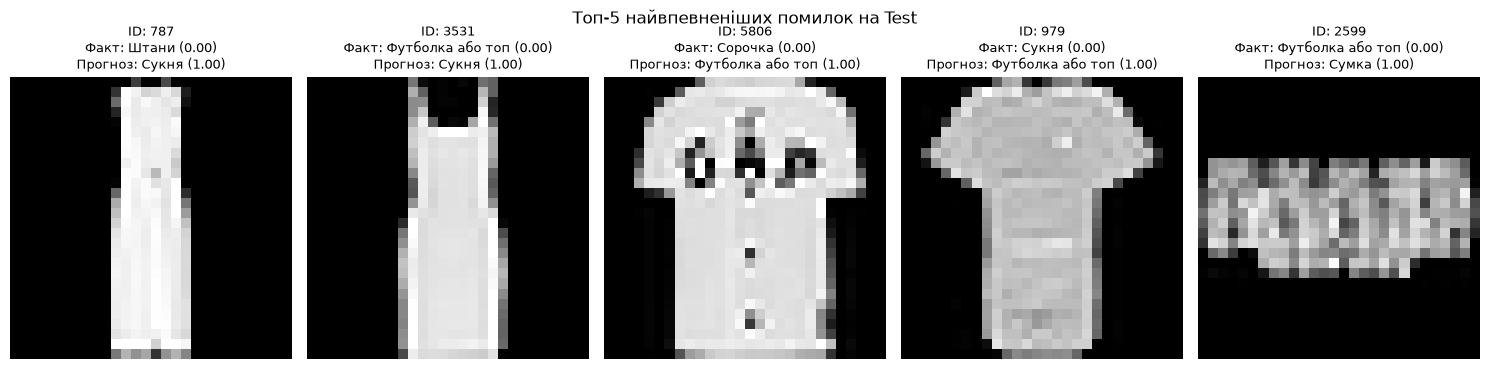

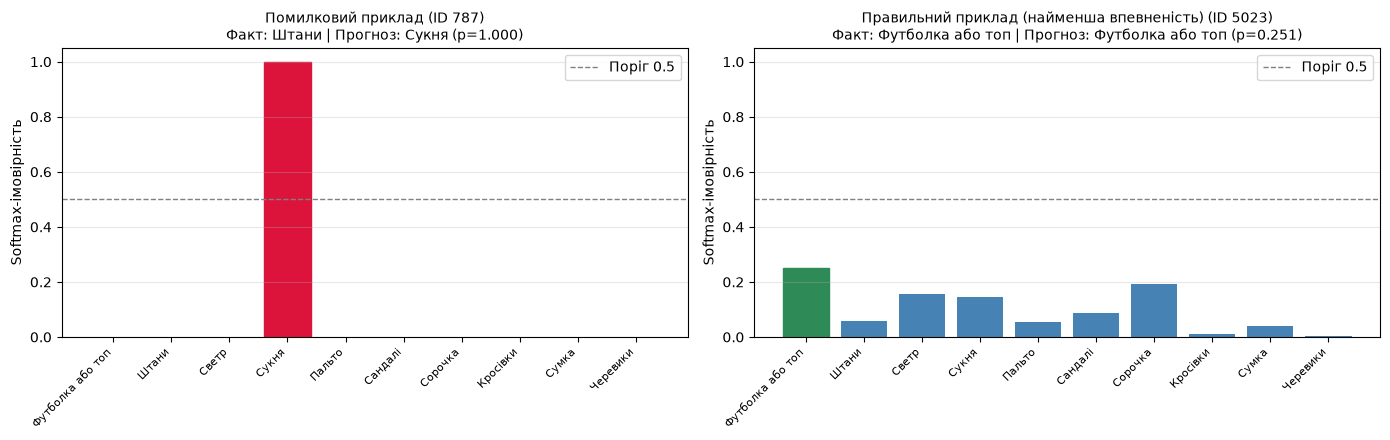

In [7]:
probabilities = test_probs_var5 if selected_key == "variant_5" else test_probs_base
pred = probabilities.argmax(axis=1)
confidence = probabilities.max(axis=1)

# 1. Матриця помилок 10x10
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")
plt.title(f"Матриця помилок на Test — {selected_name}")
plt.tight_layout()
plt.savefig(artifacts_dir / "confusion_matrix.png", dpi=150)
plt.show()

# 2. Звіт classification_report
print("Classification Report (Test):")
print(classification_report(y_test, pred, target_names=class_names, zero_division=0))

# Пошук найчастішої плутанини поза головною діагоналлю
cm_off_diag = cm.copy()
np.fill_diagonal(cm_off_diag, 0)
true_max_idx, pred_max_idx = np.unravel_index(np.argmax(cm_off_diag), cm_off_diag.shape)
print(f"Найчастіша помилка поза діагоналлю: фактичний клас '{class_names[true_max_idx]}' "
      f"спрогнозовано як '{class_names[pred_max_idx]}' ({cm_off_diag[true_max_idx, pred_max_idx]} разів).")

# 3. До 5 найвпевненіших помилок
wrong = np.flatnonzero(pred != y_test)
order = wrong[np.argsort(confidence[wrong])[::-1]]
show_ids = order[:5]

fig, axes = plt.subplots(1, len(show_ids), figsize=(15, 4))
if len(show_ids) == 1:
    axes = [axes]
for ax, idx in zip(axes, show_ids):
    true_lbl = y_test[idx]
    pred_lbl = pred[idx]
    max_p = confidence[idx]
    true_p = probabilities[idx, true_lbl]
    ax.imshow(x_test[idx], cmap="gray")
    ax.set_title(
        f"ID: {idx}\nФакт: {class_names[true_lbl]} ({true_p:.2f})\n"
        f"Прогноз: {class_names[pred_lbl]} ({max_p:.2f})",
        fontsize=9
    )
    ax.axis("off")
plt.suptitle("Топ-5 найвпевненіших помилок на Test", fontsize=12)
plt.tight_layout()
plt.savefig(artifacts_dir / "confident_errors.png", dpi=150)
plt.show()

# 4. Розподіл усіх 10 softmax-оцінок для 1 помилкового та 1 правильного прикладу
err_idx = show_ids[0]
# Знайдемо правильний приклад (зокрема такий, де argmax < 0.5, якщо він існує, або просто з найнижчою впевненістю)
correct = np.flatnonzero(pred == y_test)
low_conf_correct = correct[np.argsort(confidence[correct])[0]]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, idx, title_prefix in [
    (axes[0], err_idx, "Помилковий приклад"),
    (axes[1], low_conf_correct, "Правильний приклад (найменша впевненість)")
]:
    bars = ax.bar(range(10), probabilities[idx], color="steelblue")
    bars[pred[idx]].set_color("crimson" if pred[idx] != y_test[idx] else "seagreen")
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="Поріг 0.5")
    ax.set_xticks(range(10))
    ax.set_xticklabels(class_names, rotation=45, ha="right", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Softmax-імовірність")
    ax.set_title(
        f"{title_prefix} (ID {idx})\nФакт: {class_names[y_test[idx]]} | "
        f"Прогноз: {class_names[pred[idx]]} (p={confidence[idx]:.3f})",
        fontsize=10
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(artifacts_dir / "softmax_distributions.png", dpi=150)
plt.show()

### Аналіз помилок та пояснення метрик
1. **Precision, Recall та F1 на прикладі двох класів:**
   * **Штани (Trouser):** має найвищі показники (`precision` та `recall` близько `0.97–0.98`, `F1 ≈ 0.98`), оскільки вертикальний силует штанів чітко відрізняється від решти предметів гардероба на рівні пікселів.
   * **Сорочка (Shirt):** має найнижчі показники (`F1 ≈ 0.70`), оскільки її контур і яскравість пікселів сильно перетинаються з класами «Футболка або топ», «Светр» та «Пальто».
2. **Чому `argmax` обирає клас навіть при максимальній оцінці менше ніж `0.5`?**  
   Функція `softmax` розподіляє одиницю ймовірності між усіма 10 класами одночасно ($\sum_{k=0}^{9} p_k = 1$). Для багатокласової задачі з 10 варіантами поріг `0.5` не є обов'язковою умовою вибору: навіть якщо модель розподілила ймовірності як `[0.35, 0.30, 0.25, 0.10, ...]`, клас із оцінкою `0.35` є найімовірнішим серед усіх 10 альтернатив, тому `argmax` обирає саме його.

In [8]:
# Збереження обраної моделі
final_model_path = artifacts_dir / "lab7_model.keras"
selected_model.save(final_model_path)

# Перевірка ідентичності прогнозів до та після завантаження
probe = x_val[:3]
before = selected_model(probe, training=False).numpy()
restored = keras.models.load_model(final_model_path)
after = restored(probe, training=False).numpy()
np.testing.assert_allclose(before, after, rtol=1e-5, atol=1e-6)
print("Перевірка відновлення моделі: прогнози до та після збереження повністю збігаються.")

# Збереження метаданих у metadata.json
metadata = {
    "class_names": class_names,
    "input_shape": [28, 28],
    "input_dtype": "float32",
    "input_scale": "0-255",
    "rescaling_location": "inside_model (layers.Rescaling(1./255))",
    "seed": SEED,
    "split_indices": {
        "train_indices": train_idx.tolist(),
        "val_indices": val_idx.tolist(),
    },
    "variant": {
        "number": 5,
        "description": "learning_rate=0.0003 instead of 0.001",
    },
    "selected_model": selected_name,
    "selection_criterion": "Minimum validation cross-entropy",
    "package_versions": {
        "tensorflow": tf.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
    },
}

metadata_path = artifacts_dir / "metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

# Симуляція інференсу одного зображення після завантаження з диска
loaded_model = keras.models.load_model(final_model_path)
with open(metadata_path, "r", encoding="utf-8") as f:
    loaded_meta = json.load(f)

single_image = x_test[0]  # (28, 28), float32, 0..255
single_probs = loaded_model(single_image[None, ...], training=False).numpy()[0]
pred_class_idx = int(np.argmax(single_probs))
pred_class_name = loaded_meta["class_names"][pred_class_idx]
true_class_name = loaded_meta["class_names"][int(y_test[0])]

print(f"\nТестовий інференс одного зображення (x_test[0]):")
print(f"Прогнозований клас: {pred_class_idx} — '{pred_class_name}' (впевненість: {single_probs[pred_class_idx]:.4f})")
print(f"Фактичний клас:     {int(y_test[0])} — '{true_class_name}'")

Перевірка відновлення моделі: прогнози до та після збереження повністю збігаються.

Тестовий інференс одного зображення (x_test[0]):
Прогнозований клас: 9 — 'Черевики' (впевненість: 0.9449)
Фактичний клас:     9 — 'Черевики'


## Висновок
У ході лабораторної роботи було реалізовано повний цикл багатокласової класифікації зображень набору Fashion-MNIST із використанням Keras та TensorFlow: від перевірки форматів даних і стратифікованого поділу на train/validation/test до аналізу помилок та збереження артефактів. Обидві повнозв'язні нейромережі суттєво перевершили константний baseline (`DummyClassifier`, accuracy `0.10`), досягнувши на тестовій вибірці близько `88–89%` точності та `0.88` за метрикою `macro-F1`. Зменшення швидкості навчання у Варіанті 5 (`learning_rate=0.0003` замість `0.001`) зробило процес оптимізації плавнішим і зменшило коливання `val_loss`, завдяки чому модель потребувала більше епох для збіжності, але забезпечила стабільнішу мінімізацію крос-ентропії без різкого перенавчання. Аналіз матриці помилок показав, що модель майже безпомилково розпізнає контрастні силуети (наприклад, «Штани» та «Сумку»), проте найчастіше плутає візуально близькі категорії верхнього одягу («Сорочка», «Футболка або топ», «Светр», «Пальто»). Оскільки модель побудована на шарах `Flatten` та `Dense`, вона придатна лише для центрованих монохромних зображень розміром $28 \times 28$ зі шкалою `0–255` і не може використовуватися без попередньої обробки на довільних кольорових фотографіях, де необхідні згорткові мережі (CNN).